# 02 · Φ(l) landscapes: block size, chain length, spectral window

These are $(g, h)$ landscapes of the block metric $\Phi(l)$ from notebook 01 for the mixed-field Ising chain, on the same grid ($g \in [1, 2]$, $h \in [0.2, 0.8]$):

1. $\Phi(0)$, $\Phi(1)$, $\Phi(2)$ for $L = 9$–$12$.
2. Six-spin blocks, $\Phi(5)$, for $L = 9$–$12$, plus the two half-chain blocks at $L = 12$.
3. Sensitivity of $\Phi(5)$ at $L = 12$ to the width of the spectral window.

All landscapes come from `scripts/compute_landscapes.py`, which diagonalizes each grid point once and evaluates every metric on the same eigenvectors. Narrower spectral windows use the central columns of the 50 % window.

In [1]:
from pathlib import Path

import numpy as np

from spin_eth import PRX_G, PRX_H, spectral_window
from spin_eth.io import load_npz
from spin_eth.plotting import landscape_panels, plot_min_scaling
from spin_eth.scans import grid_minimum

RESULTS, FIGURES = Path("../results"), Path("../figures")
FIGURES.mkdir(exist_ok=True)
L_values = [9, 10, 11, 12]
land = {L: load_npz(RESULTS / "landscapes" / f"mfim_L{L}.npz") for L in L_values}
g, h = land[9]["g"], land[9]["h"]


def key(l, positions="all", frac=0.5):
    return f"l{l}_pos{positions}_frac{frac:g}"


def print_minima(rows, extra_header=""):
    # rows: (label, landscape) or (label, landscape, extra column value)
    print(f"{'':>24}  {'min Phi':>11}  {'g*':>6}  {'h*':>6}  {'|g*-1.08|':>9}  {'|h*-0.30|':>9}  {extra_header}")
    for label, data, *extra in rows:
        v, gm, hm = grid_minimum(data, g, h)
        print(f"{label:>24}  {v:11.4e}  {gm:6.3f}  {hm:6.3f}  {abs(gm - PRX_G):9.4f}  {abs(hm - PRX_H):9.4f}  {extra[0] if extra else ''}")

## 1. Φ(0), Φ(1), Φ(2) for L = 9–12

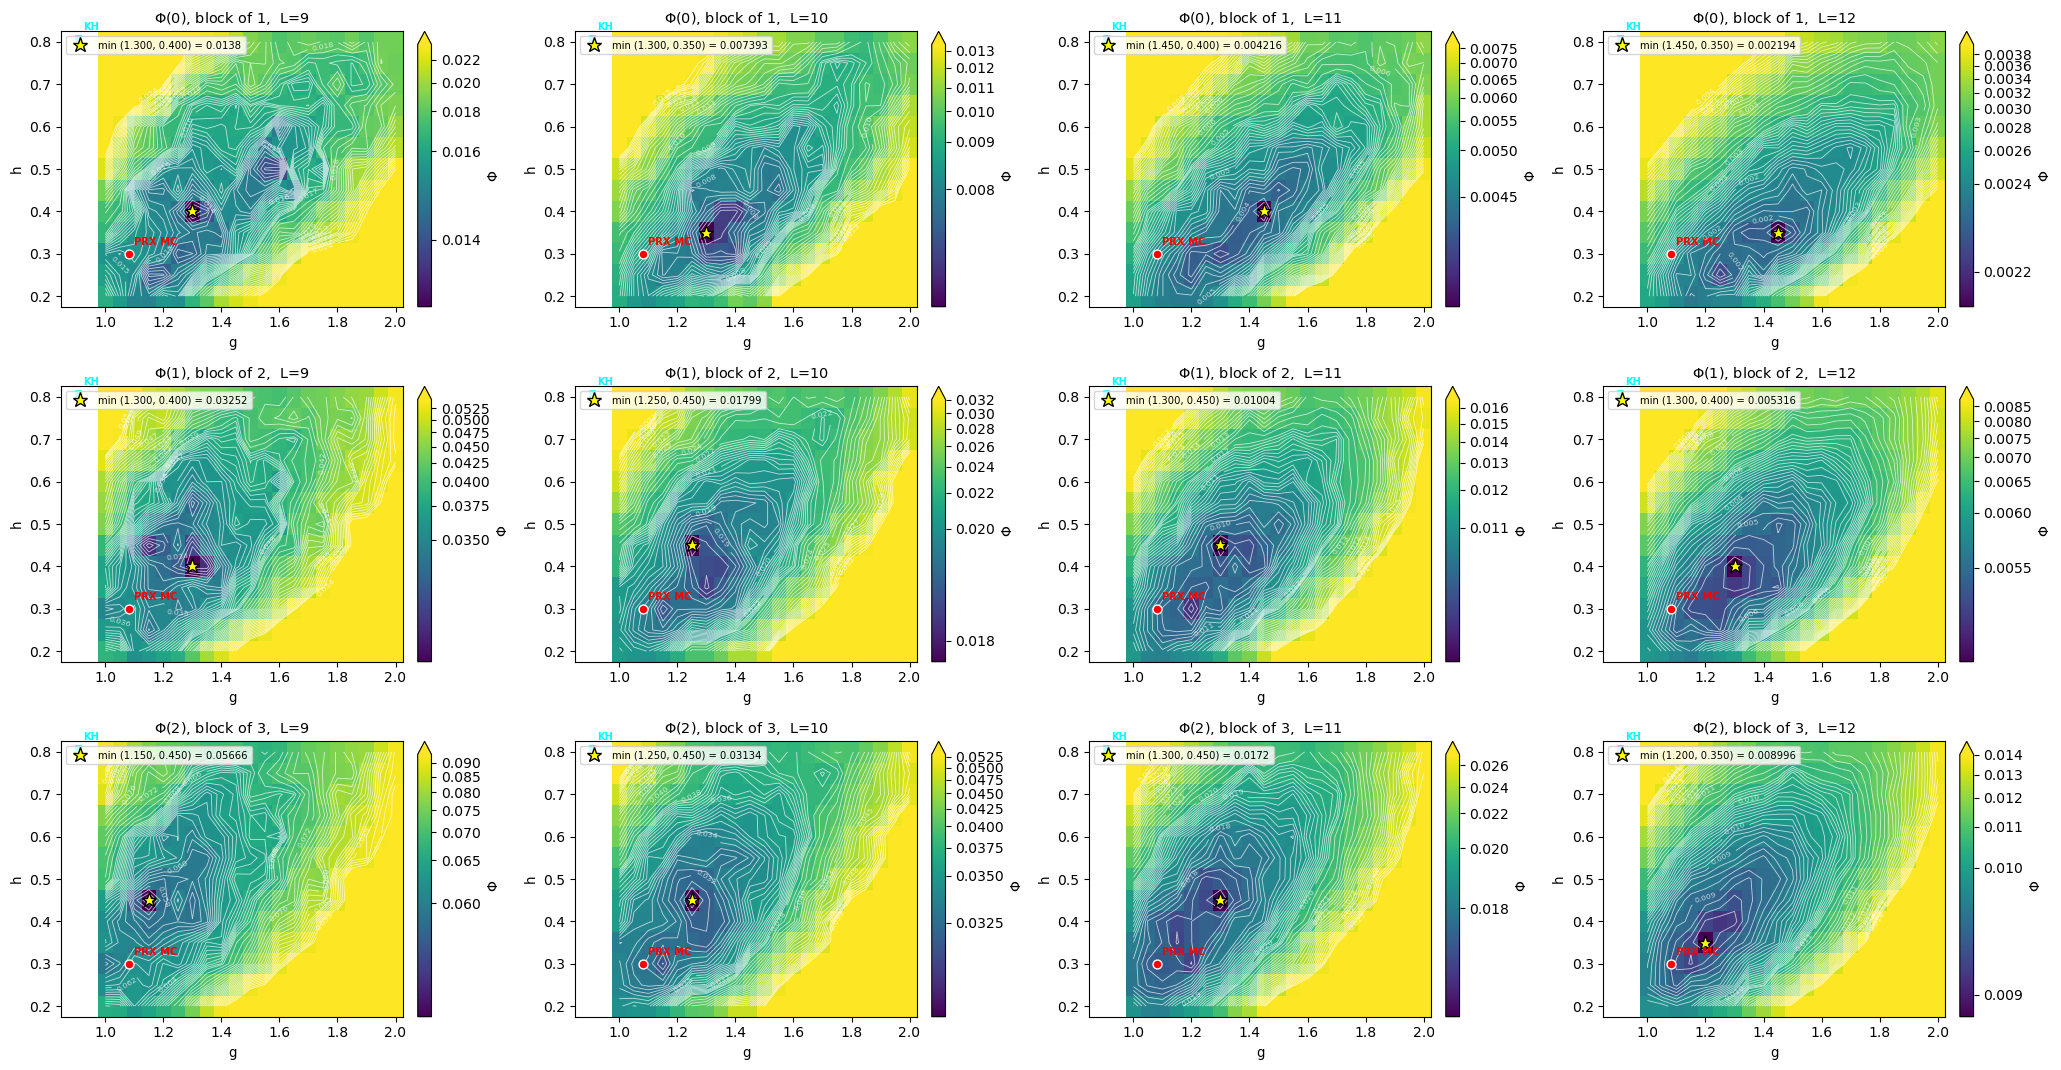

                              min Phi      g*      h*  |g*-1.08|  |h*-0.30|  
                l=0, L=9   1.3805e-02   1.300   0.400     0.2200     0.1000  
               l=0, L=10   7.3933e-03   1.300   0.350     0.2200     0.0500  
               l=0, L=11   4.2159e-03   1.450   0.400     0.3700     0.1000  
               l=0, L=12   2.1944e-03   1.450   0.350     0.3700     0.0500  
                l=1, L=9   3.2525e-02   1.300   0.400     0.2200     0.1000  
               l=1, L=10   1.7990e-02   1.250   0.450     0.1700     0.1500  
               l=1, L=11   1.0035e-02   1.300   0.450     0.2200     0.1500  
               l=1, L=12   5.3164e-03   1.300   0.400     0.2200     0.1000  
                l=2, L=9   5.6659e-02   1.150   0.450     0.0700     0.1500  
               l=2, L=10   3.1338e-02   1.250   0.450     0.1700     0.1500  
               l=2, L=11   1.7203e-02   1.300   0.450     0.2200     0.1500  
               l=2, L=12   8.9958e-03   1.200   0.350     0.1200

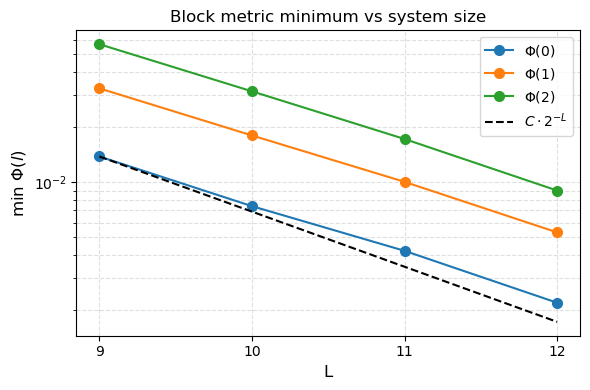

In [2]:
fig = landscape_panels([(land[L][key(l)], g, h, f"$\\Phi({l})$, block of {l + 1},  L={L}")
                        for l in (0, 1, 2) for L in L_values], ncols=4)
fig.savefig(FIGURES / "phi_landscapes.png", dpi=80, bbox_inches="tight")
print_minima([(f"l={l}, L={L}", land[L][key(l)]) for l in (0, 1, 2) for L in L_values])
fig = plot_min_scaling(L_values, {f"$\\Phi({l})$": [grid_minimum(land[L][key(l)], g, h)[0] for L in L_values] for l in (0, 1, 2)},
                       title="Block metric minimum vs system size", ylabel=r"min $\Phi(l)$")
fig.savefig(FIGURES / "phi_min_scaling.png", dpi=110, bbox_inches="tight");

## 2. Six-spin blocks: Φ(5)

Blocks of 6 spins ($64 \times 64$ reduced density matrices) fit in $L - 5$ positions: 4 at $L = 9$, up to 7 at $L = 12$. At $L = 12$ the blocks starting at $j = 0$ (sites 0–5) and $j = 6$ (sites 6–11) are the two halves of the chain. Every other position leaves environments of unequal size on either side.

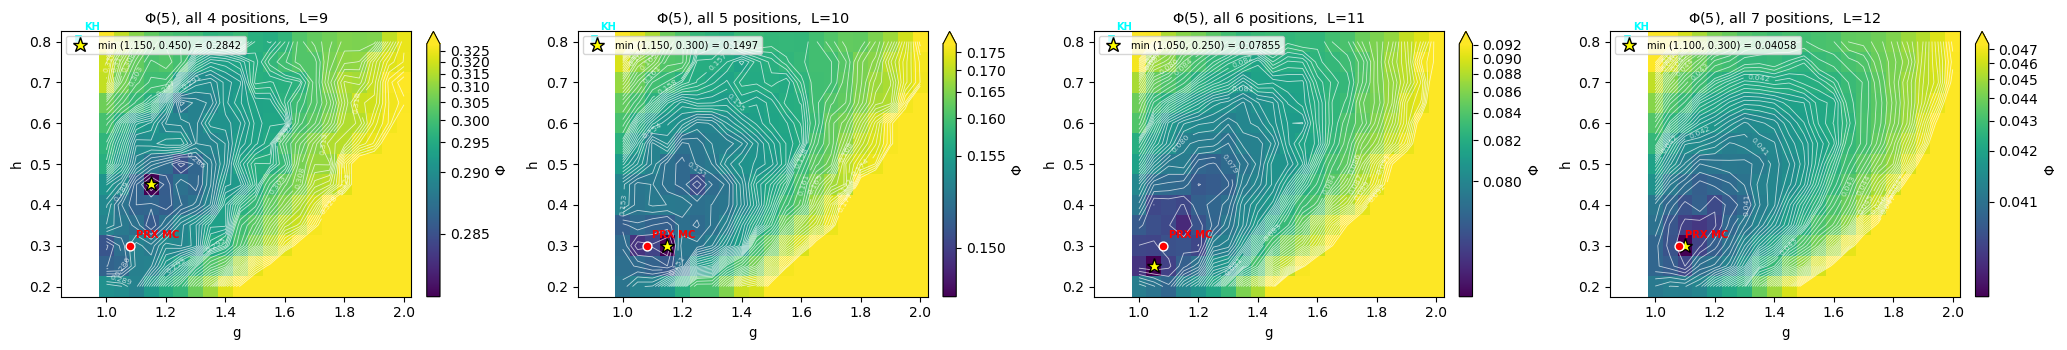

                              min Phi      g*      h*  |g*-1.08|  |h*-0.30|  
       L=9 (4 positions)   2.8418e-01   1.150   0.450     0.0700     0.1500  
      L=10 (5 positions)   1.4975e-01   1.150   0.300     0.0700     0.0000  
      L=11 (6 positions)   7.8545e-02   1.050   0.250     0.0300     0.0500  
      L=12 (7 positions)   4.0584e-02   1.100   0.300     0.0200     0.0000  


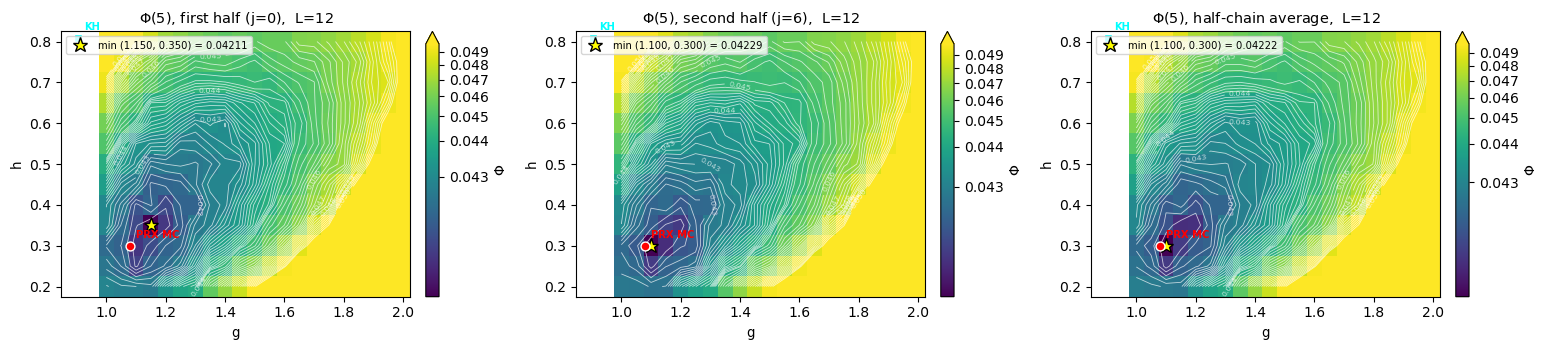

                              min Phi      g*      h*  |g*-1.08|  |h*-0.30|  
        first half (j=0)   4.2107e-02   1.150   0.350     0.0700     0.0500  
       second half (j=6)   4.2294e-02   1.100   0.300     0.0200     0.0000  
      half-chain average   4.2218e-02   1.100   0.300     0.0200     0.0000  
         all 7 positions   4.0584e-02   1.100   0.300     0.0200     0.0000  


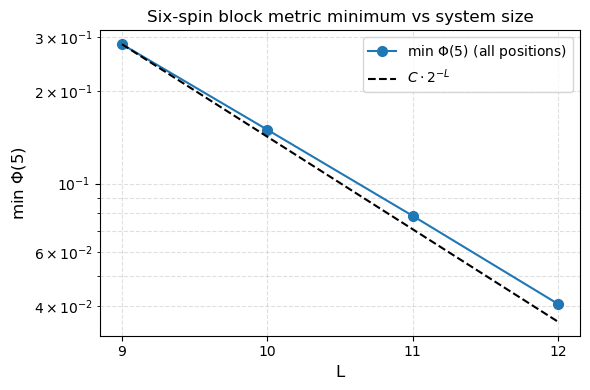

In [3]:
landscape_panels([(land[L][key(5)], g, h, f"$\\Phi(5)$, all {L - 5} positions,  L={L}") for L in L_values], ncols=4);
print_minima([(f"L={L} ({L - 5} positions)", land[L][key(5)]) for L in L_values])

half = {"first half (j=0)": land[12][key(5, "0")], "second half (j=6)": land[12][key(5, "6")]}
half["half-chain average"] = 0.5 * (half["first half (j=0)"] + half["second half (j=6)"])
landscape_panels([(d, g, h, f"$\\Phi(5)$, {name},  L=12") for name, d in half.items()], ncols=3);
print_minima(list(half.items()) + [("all 7 positions", land[12][key(5)])])

plot_min_scaling(L_values, {r"min $\Phi(5)$ (all positions)": [grid_minimum(land[L][key(5)], g, h)[0] for L in L_values]},
                 title="Six-spin block metric minimum vs system size", ylabel=r"min $\Phi(5)$");

## 3. Spectral window, Φ(5) at L = 12

The same metric over the middle 50 %, 20 %, 10 % and 5 % of the spectrum.

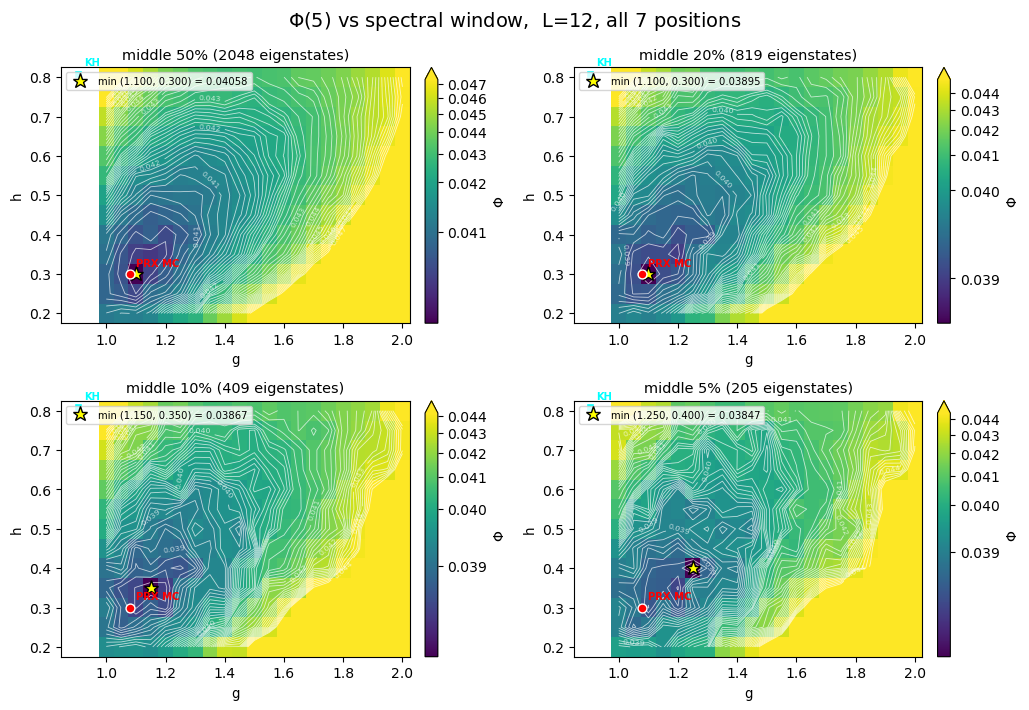

                              min Phi      g*      h*  |g*-1.08|  |h*-0.30|  n_eig
              middle 50%   4.0584e-02   1.100   0.300     0.0200     0.0000  2048
              middle 20%   3.8953e-02   1.100   0.300     0.0200     0.0000  819
              middle 10%   3.8669e-02   1.150   0.350     0.0700     0.0500  409
               middle 5%   3.8470e-02   1.250   0.400     0.1700     0.1000  205


In [4]:
fracs = [0.50, 0.20, 0.10, 0.05]
n_eig = {f: (lambda lo, hi: hi - lo + 1)(*spectral_window(2**12, f)) for f in fracs}
landscape_panels([(land[12][key(5, frac=f)], g, h, f"middle {f:.0%} ({n_eig[f]} eigenstates)") for f in fracs],
                 ncols=2, suptitle="$\\Phi(5)$ vs spectral window,  L=12, all 7 positions");
print_minima([(f"middle {f:.0%}", land[12][key(5, frac=f)], n_eig[f]) for f in fracs], extra_header="n_eig")